# The CLT and standard error on the WNBA 2025 shots

##### One row is one shot. The outcome `made_flag` is 1 when the shot is made and 0 when it is missed. Everything below reads the frozen clean file `wnba_clean.csv`, which sits at the top of the repository, so from `topics/` the path is `../wnba_clean.csv`. Seed 651.

In [1]:
import numpy as np 
import pandas as pd

In [2]:
df = pd.read_csv('../wnba_clean.csv')
y = df['made_flag']
n = len(y)
print("shots:", n, " makes:", int(y.sum()))

shots: 38535  makes: 16926


## 1. The make rate, its standard error and a 95% interval

In [3]:
p_hat = y.mean()
se = np.sqrt(p_hat * (1 - p_hat) / n)        # SE of a rate = sqrt(p(1-p)/n)
half = 1.96 * se                             # half-width of the 95% interval
print("rate, SE, half:", round(p_hat, 4), round(se, 4), round(half, 4))
print("95% interval:", round(p_hat - half, 4), round(p_hat + half, 4))

rate, SE, half: 0.4392 0.0025 0.005
95% interval: 0.4343 0.4442


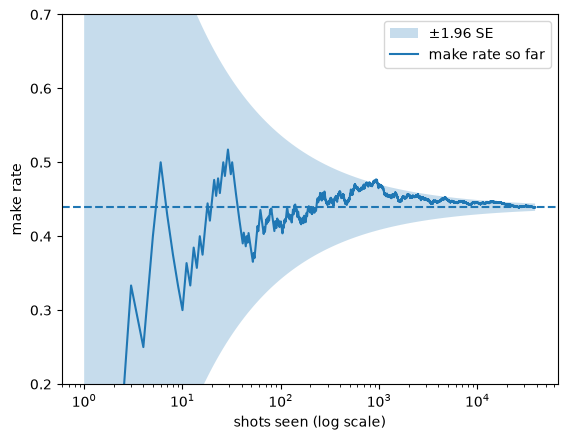

In [4]:
import matplotlib.pyplot as plt
rng = np.random.default_rng(651)
order = rng.permutation(y.to_numpy())            # shots in random order
k = np.arange(1, n + 1)
running = np.cumsum(order) / k                   # make rate after k shots
band = 1.96 * np.sqrt(p_hat * (1 - p_hat) / k)   # the 95% band shrinks as k grows
plt.fill_between(k, p_hat - band, p_hat + band, alpha=0.25, label="±1.96 SE")
plt.plot(k, running, label="make rate so far")
plt.axhline(p_hat, ls="--"); plt.xscale("log"); plt.ylim(0.2, 0.7)
plt.xlabel("shots seen (log scale)"); plt.ylabel("make rate"); plt.legend(); plt.show()

## 2. Draw 2,000 random subsamples of size 100 and of size 400

In [5]:
rng = np.random.default_rng(651)
shots = y.to_numpy()
spread = {}
for size in (100, 400):
    est = [rng.choice(shots, size=size,
           replace=False).mean()
           for _ in range(2000)]
    spread[size] = np.std(est, ddof=1)
    formula = np.sqrt(p_hat*(1-p_hat)/size)
    print(size, round(spread[size], 4),
          round(formula, 4))
print("ratio:", round(spread[100]/spread[400], 2))

100 0.0485 0.0496
400 0.0252 0.0248
ratio: 1.92


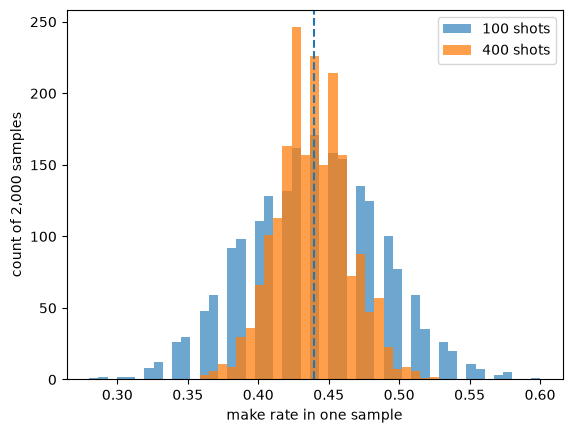

In [6]:
rng = np.random.default_rng(651)            # same seed, same draws as the cell above
est = {size: [rng.choice(shots, size=size, replace=False).mean() for _ in range(2000)]
       for size in (100, 400)}
bins = np.linspace(0.28, 0.60, 50)
plt.hist(est[100], bins=bins, alpha=0.65, label="100 shots")
plt.hist(est[400], bins=bins, alpha=0.75, label="400 shots")
plt.axvline(p_hat, ls="--"); plt.xlabel("make rate in one sample")
plt.ylabel("count of 2,000 samples"); plt.legend(); plt.show()

## 3. The rows are not independent: count the unit, not the row

In [7]:
print("naive SE:", round(se, 4))
print("unit units each SE deff n_eff")
for unit in ("player_id", "game_id"):
    g = df.groupby(unit)["made_flag"]
    print(g)
    g = g.agg(["sum", "count"])
    print(g)
    r = g["sum"] - g["count"] * p_hat          # each unit's makes minus what p_hat predicts
    print(r)
    se_cl = np.sqrt((r**2).sum()) / n          # SE with this unit as the independent one
    deff = (se_cl / se) ** 2                   # how much the variance grows
    print(unit, len(g), round(n / len(g)), round(se_cl, 4), round(deff, 2), int(n / deff))

naive SE: 0.0025
unit units each SE deff n_eff
           sum  count
player_id            
201886     105    257
202250     260    593
202252      59    159
202641      26     76
202664      29     66
...        ...    ...
1642817     37    109
1642818     38    105
1642820     13     27
1642822     19     50
1642841     14     39

[179 rows x 2 columns]
player_id
201886     -7.883924
202250     -0.467575
202252    -10.838692
202641     -7.382016
202664      0.010354
             ...    
1642817   -10.876839
1642818    -8.119891
1642820     1.140599
1642822    -2.961853
1642841    -3.130245
Length: 179, dtype: float64
player_id 179 215 0.0056 4.82 7990
            sum  count
game_id               
1022500001   61    135
1022500002   65    132
1022500003   52    126
1022500004   58    154
1022500005   63    154
...         ...    ...
1022500282   59    134
1022500283   66    133
1022500284   67    142
1022500285   48    133
1022500286   69    151

[286 rows x 2 columns]
game_id
10225000

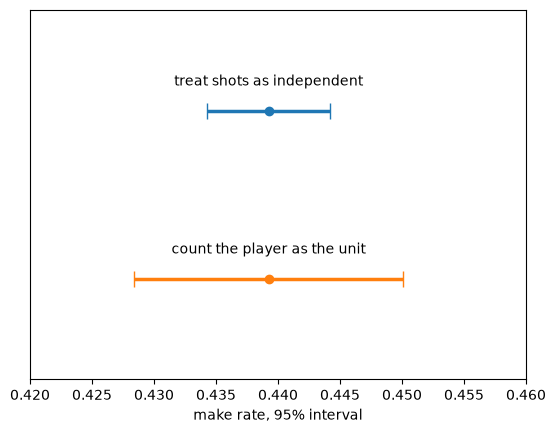

In [8]:
g = df.groupby("player_id")["made_flag"].agg(["sum", "count"])
se_player = np.sqrt(((g["sum"] - g["count"] * p_hat) ** 2).sum()) / n
for i, (label, s) in enumerate([("treat shots as independent", se), ("count the player as the unit", se_player)]):
    plt.errorbar(p_hat, 1 - i, xerr=1.96 * s, fmt="o", capsize=6, lw=2.5)
    plt.text(p_hat, 1 - i + 0.15, label, ha="center")
plt.ylim(-0.6, 1.6); plt.yticks([]); plt.xlim(0.42, 0.46)
plt.xlabel("make rate, 95% interval"); plt.show()

## AI Note

I used Claude (Anthropic) to help me write and check this code. I ran every cell on my laptop and can explain every line. The words on the slides (CLT Presentation) and any interpretation of values are my own.